# Phase 6a: failure analysis, error decomposition, EOL events, conformal intervals

Consumes the saved Phase 5b Protocol D out-of-fold predictions. Trains nothing, selects nothing with batch-3 data, writes only to `outputs/phase6a`. Phase 5b and the gate verdict are frozen. All stage, subset and interval tables are descriptive.

## 1. Setup and guards

In [1]:
import os, sys, json, math, time, hashlib, warnings, datetime
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import lfilter

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
T0 = time.time()

# ------------------------------------------------------------------ frozen facts
GATE_SHA     = "40df2fb82096e994f8bf7b8084433bb5ca148d3fa92c780461f68c0c4247d901"   # outputs/phase4/week2_gate.json
MODULE_SHA   = "fc53e37d506ebe51f6e4d71819c4b047de5bc38456669a160183531fbefebea6"   # src/soh_deep_v2.py (CRLF -> LF)
VERDICT_SHA  = "2f59f82a7c7d8940636b55d7fd3397760d4486569d95575c802dbd02df69b1bb"   # gate_verdict.json
EXPECTED_D_ROWS = 55963
SEEDS_DEEP   = [42, 43, 44, 45, 46]
DEEP_MODELS, COMP_MODELS = ["M0", "M1p"], ["B3r", "B4r"]
ALL_MODELS   = DEEP_MODELS + COMP_MODELS
WINDOWS_ALL  = ["W310", "W305", "W300", "W280", "W240", "WFULL"]
M1P_WINDOWS  = ["W300", "W240"]
STITCHED     = [f"b1c{i}" for i in range(5)]
DEFECTIVE    = "b2c40"
SENS_CELLS   = ["b1c8", "b1c10", "b1c12", "b1c13", "b1c22"]
WIN_ANALYSIS = ["W300", "W240", "W310"]
MODELS_ANALYSIS = ["M0", "M1p", "B4r", "B3r"]
B_BOOT, SEED_BOOT = 5000, 42
FORCE_REBUILD_CACHE = False          # True: re-read the Phase 5b parquet files instead of the phase6a ensemble cache
HEATMAP_VMAX = None                  # set to the colour-scale max of the earlier M0 map to share it exactly; None = derived from M0 W300

# ------------------------------------------------------------------ paths
_cwd = Path.cwd().resolve()
ROOT = next((p for p in [_cwd, *_cwd.parents] if (p / "notebooks").is_dir() and (p / "data").is_dir()), None)
if ROOT is None:
    raise RuntimeError(f"Cannot resolve project ROOT (parent of notebooks/) from {_cwd}")
OUT = ROOT / "outputs" / "phase6a"
FIG = OUT / "figures"
CACHE6 = OUT / "cache"
for _d in (OUT, FIG, CACHE6):
    _d.mkdir(parents=True, exist_ok=True)

P_GATE     = ROOT / "outputs/phase4/week2_gate.json"
P_MODULE   = ROOT / "src/soh_deep_v2.py"
P_CACHE5B  = ROOT / "outputs/phase5b/cache"
P_DEEPRES  = ROOT / "outputs/phase5b/deep_results.csv"
P_BYCELL   = ROOT / "outputs/phase5b/deep_by_cell.csv"
P_SELCFG   = ROOT / "outputs/phase5b/selected_configs.csv"
P_LABELS   = ROOT / "data/processed/labels_table_v2.parquet"
P_CYCLES   = ROOT / "data/processed/cycles_table.parquet"
P_LIFE     = ROOT / "outputs/phase3/kept_cells_groups_strata.csv"
P_SPLITS   = next((p for p in [ROOT / "data/processed/splits/protocol_D.csv",
                               *sorted((ROOT / "outputs/phase3").rglob("protocol_D.csv"))] if p.exists()),
                  ROOT / "data/processed/splits/protocol_D.csv")


def _verdict_candidates():
    c = [ROOT / "outputs/phase5b/gate_verdict.json", ROOT / "outputs/phase5/gate_verdict.json"]
    c += sorted(p for p in (ROOT / "outputs").rglob("gate_verdict.json") if "phase6a" not in p.parts)
    seen, res = set(), []
    for p in c:
        if p.exists() and p not in seen:
            seen.add(p); res.append(p)
    return res


# ------------------------------------------------------------------ checks and guarded writes
CHECKS, WRITTEN = [], []


class Phase6aFail(RuntimeError):
    pass


def dump_checks(partial=False, extra=None):
    n = lambda s: sum(c["level"] == s for c in CHECKS)
    rep = {"phase": "6a", "created": datetime.datetime.now().isoformat(timespec="seconds"), "root": str(ROOT),
           "partial": partial, "n_pass": n("PASS"), "n_warn": n("WARN"), "n_fail": n("FAIL"), "n_info": n("INFO"),
           "checks": CHECKS}
    if extra:
        rep.update(extra)
    (OUT / "verification_report.json").write_text(json.dumps(rep, indent=2, default=str), encoding="utf-8")


def check(name, ok, detail="", severity="FAIL"):
    status = "PASS" if ok else severity
    CHECKS.append({"name": name, "level": status, "detail": str(detail)})
    print(f"[{status:4s}] {name}" + (f"  |  {detail}" if str(detail) else ""))
    if (not ok) and severity == "FAIL":
        dump_checks(partial=True)
        raise Phase6aFail(f"{name}: {detail}")


def info(name, detail=""):
    CHECKS.append({"name": name, "level": "INFO", "detail": str(detail)})
    print(f"[INFO] {name}" + (f"  |  {detail}" if str(detail) else ""))


def _guard(p):
    p = Path(p).resolve()
    if OUT.resolve() not in p.parents:
        raise Phase6aFail(f"refusing to write outside {OUT}: {p}")
    return p


def save_csv(df, name):
    p = _guard(OUT / name); df.to_csv(p, index=False); WRITTEN.append(p); return p


def save_text(text, name):
    p = _guard(OUT / name); p.write_text(text, encoding="utf-8"); WRITTEN.append(p); return p


def save_fig(fig, name):
    p = _guard(FIG / name); fig.savefig(p, dpi=150, bbox_inches="tight", facecolor="white"); WRITTEN.append(p); plt.show(); plt.close(fig); return p


# ------------------------------------------------------------------ frozen-file hashes (start)
def sha_variants(p):
    b = Path(p).read_bytes()
    return hashlib.sha256(b).hexdigest(), hashlib.sha256(b.replace(b"\r\n", b"\n")).hexdigest()


def hash_state():
    st = {}
    for key, p, exp, raw_ok in [("gate", P_GATE, GATE_SHA, True), ("module", P_MODULE, MODULE_SHA, False),
                                ("verdict", P_VERDICT, VERDICT_SHA, True)]:
        raw, lf = sha_variants(p)
        ok = (lf == exp) or (raw_ok and raw == exp)
        st[key] = {"path": str(p), "raw": raw, "lf": lf, "ok": ok, "mtime_ns": p.stat().st_mtime_ns}
    return st


for _p in (P_GATE, P_MODULE):
    check(f"frozen file exists: {_p.relative_to(ROOT)}", _p.exists(), _p)
_vc = _verdict_candidates()
check("gate_verdict.json found", len(_vc) > 0, ", ".join(str(v.relative_to(ROOT)) for v in _vc) or "none under outputs/")
P_VERDICT = next((v for v in _vc if sha_variants(v)[0] == VERDICT_SHA or sha_variants(v)[1] == VERDICT_SHA), _vc[0])

HASH0 = hash_state()
for _k, _lab in [("gate", "week2_gate.json"), ("module", "soh_deep_v2.py (CRLF->LF)"), ("verdict", "gate_verdict.json")]:
    check(f"sha256 matches frozen value at start: {_lab}", HASH0[_k]["ok"], HASH0[_k]["lf" if _k == "module" else "raw"][:16] + "...")
print("verdict file (frozen, not recomputed or relabelled):")
print("   ", P_VERDICT.read_text(encoding="utf-8")[:700].replace("\n", "\n    "))
print("headline W300 FAIL (M0 0.836 vs target 0.760) | companion W240 PASS (M0 0.530 vs 0.557)  [frozen]")

# ------------------------------------------------------------------ environment and inputs
try:
    import torch
    _cuda = torch.cuda.is_available()
    _txt = f"torch {torch.__version__}, cuda available={_cuda}" + (f", device={torch.cuda.get_device_name(0)}" if _cuda else "")
    check("GPU/CUDA (informational, not needed: nothing is trained)", _cuda, _txt, severity="WARN")
except Exception as _e:
    check("GPU/CUDA (informational, not needed: nothing is trained)", False, f"torch not importable: {_e}", severity="WARN")

import pyarrow.parquet as pq
_cache_files = sorted(p for p in P_CACHE5B.glob("final_*.parquet") if p.is_file())      # top level only; cache/smoke ignored
for _p in (P_DEEPRES, P_BYCELL, P_SELCFG, P_LABELS, P_CYCLES, P_LIFE, P_SPLITS):
    check(f"input exists: {_p.relative_to(ROOT)}", _p.exists(), _p)
check("Phase 5b cache: final_*.parquet files (top level)", len(_cache_files) > 0,
      f"{len(_cache_files)} files; subfolders ignored")
_PRED_COLS = ["window", "model", "repeat", "outer_fold", "seed", "row_id", "cell_id", "pred_pp"]
for _p in _cache_files:
    _missing = [c for c in _PRED_COLS if c not in pq.read_schema(_p).names]
    check(f"schema {_p.name}", not _missing, f"missing: {_missing}" if _missing else "")
_cyc_names = pq.read_schema(P_CYCLES).names
print("cycles_table.parquet columns:", _cyc_names)
_lab_names = pq.read_schema(P_LABELS).names
print("labels_table_v2.parquet columns:", _lab_names)
_need_lab = ["row_id", "cell_id", "batch", "cycle_number", "q0", "soh_nom", "scored2"]
check("labels_table_v2 schema", all(c in _lab_names for c in _need_lab), [c for c in _need_lab if c not in _lab_names])

[PASS] frozen file exists: outputs\phase4\week2_gate.json  |  C:\workstation\3RD YEAR\Battery-Health-Estimation\outputs\phase4\week2_gate.json
[PASS] frozen file exists: src\soh_deep_v2.py  |  C:\workstation\3RD YEAR\Battery-Health-Estimation\src\soh_deep_v2.py
[PASS] gate_verdict.json found  |  outputs\phase5b\gate_verdict.json, outputs\phase5b\smoke\gate_verdict.json
[PASS] sha256 matches frozen value at start: week2_gate.json  |  40df2fb82096e994...
[PASS] sha256 matches frozen value at start: soh_deep_v2.py (CRLF->LF)  |  fc53e37d506ebe51...
[PASS] sha256 matches frozen value at start: gate_verdict.json  |  2f59f82a7c7d8940...
verdict file (frozen, not recomputed or relabelled):
    {
      "created": "2026-11-03T01:22:59",
      "config": "full",
      "primary_model": "M0",
      "boot": 5000,
      "seed": 42,
      "gate_sha256": "40df2fb82096e994f8bf7b8084433bb5ca148d3fa92c780461f68c0c4247d901",
      "module_sha256": "fc53e37d506ebe51f6e4d71819c4b047de5bc38456669a160183531fbe

In [2]:
# ------------------------------------------------------------------ development cells and splits
splits = pd.read_csv(P_SPLITS)
check("splits schema", {"repeat", "outer_fold", "cell_id", "role"} <= set(splits.columns), list(splits.columns))
dev_cells = sorted(splits.cell_id.unique())
_nb1 = sum(c.startswith("b1c") for c in dev_cells); _nb2 = sum(c.startswith("b2c") for c in dev_cells)
check("84 development cells (41 batch-1 + 43 batch-2)", (len(dev_cells), _nb1, _nb2) == (84, 41, 43), (len(dev_cells), _nb1, _nb2))
check("no batch-3 / sensitivity cells in splits", not any(c.startswith("b3") for c in dev_cells) and not (set(SENS_CELLS) & set(dev_cells)))
REPS = sorted(int(r) for r in splits.repeat.unique())
FOLDS = sorted(int(f) for f in splits.outer_fold.unique())
check("3 repeats x 6 outer folds", (len(REPS), len(FOLDS)) == (3, 6), (REPS, FOLDS))
DEV_SET = set(dev_cells)

# ------------------------------------------------------------------ labels: development rows only
_lab = pd.read_parquet(P_LABELS)
_lab = _lab[_lab.cell_id.isin(DEV_SET)].copy()                      # batch 3 / sensitivity cells never leave this line
_lab["scored2"] = _lab["scored2"].fillna(False).astype(bool)
_flag_cols_lab = [c for c in _lab.columns if c.startswith("flag_")]
D = _lab[_lab.scored2].copy()
D["y"] = 100.0 * D["soh_nom"].astype(float)
D = D.sort_values(["cell_id", "cycle_number", "row_id"]).reset_index(drop=True)
check("development rows D = scored2 & 84 cells", len(D) == EXPECTED_D_ROWS, f"{len(D):,} rows (expected {EXPECTED_D_ROWS:,})")
check("row_id unique in D", D.row_id.is_unique)
check("no NaN in y / cycle_number", not (D.y.isna().any() or D.cycle_number.isna().any()))
check("D covers all 84 cells", D.cell_id.nunique() == 84, D.cell_id.nunique())
info("labels 'batch' column values (batch is derived from the cell_id prefix)", sorted(map(str, _lab["batch"].unique()))[:6])
_dup = int(D.duplicated(["cell_id", "cycle_number"]).sum())
check("cycle_number unique within cell (EMA ordering well defined)", _dup == 0, f"{_dup} duplicated (cell, cycle)", severity="WARN")

cells = D.cell_id.unique()
COUNTS = D.groupby("cell_id", sort=False).size().values
assert list(cells) == sorted(cells) and COUNTS.sum() == len(D)
NC, N, R = len(cells), len(D), len(REPS)
STARTS = np.r_[0, np.cumsum(COUNTS)[:-1]]
CELL_CODE = np.repeat(np.arange(NC), COUNTS)
Y = D.y.values.astype(float)
CYC = D.cycle_number.values.astype(float)
BATCH = np.array([int(c[1]) for c in cells])
IS_ST = np.isin(cells, STITCHED); IS_DEF = cells == DEFECTIVE
check("cell arrays contain no batch-3 / sensitivity cells", not (set(cells) & set(SENS_CELLS)) and not any(c.startswith("b3") for c in cells))

_life = pd.read_csv(P_LIFE)
check("life table schema", {"cell_id", "life"} <= set(_life.columns), list(_life.columns))
_life = _life[_life.cell_id.isin(DEV_SET)].drop_duplicates("cell_id").set_index("cell_id")
LIFE = _life["life"].reindex(cells).values.astype(float)
check("life available for all 84 cells", not np.isnan(LIFE).any())
LIFE_ROW = LIFE[CELL_CODE]
TENTH = np.clip(np.floor(10.0 * CYC / LIFE_ROW), 0, 9).astype(int)
TENTH_LAB = [f"{10*i}-{10*(i+1)}%" for i in range(10)]
LIFE_CUTS = np.quantile(LIFE, [1 / 3, 2 / 3])
TERT = np.digitize(LIFE, LIFE_CUTS)
TERT_LAB = ["short", "mid", "long"]
check("life tertile cuts close to ~493 / ~710", abs(LIFE_CUTS[0] - 493) < 15 and abs(LIFE_CUTS[1] - 710) < 15,
      f"{LIFE_CUTS[0]:.1f} / {LIFE_CUTS[1]:.1f}", severity="WARN")
info("rows beyond stated life (kept in tenth 10)", f"{int((CYC > LIFE_ROW).sum()):,}")

# ------------------------------------------------------------------ dirty-data counters (labels masks, flag_* columns)
dirty = pd.DataFrame({"cell_id": cells})
_n_all = _lab.groupby("cell_id").size().reindex(cells).values
dirty["rows_dropped_by_masks"] = _n_all - COUNTS
if _flag_cols_lab:
    _fl = _lab[_flag_cols_lab].apply(pd.to_numeric, errors="coerce").fillna(0) > 0
    dirty["flag_rows_labels"] = _fl.any(axis=1).groupby(_lab.cell_id).sum().reindex(cells).fillna(0).astype(int).values
else:
    dirty["flag_rows_labels"] = 0
_flag_cols_cyc = [c for c in _cyc_names if c.startswith("flag_")]
if _flag_cols_cyc and "cell_id" in _cyc_names:
    _ct = pd.read_parquet(P_CYCLES, columns=["cell_id"] + _flag_cols_cyc)
    _ct = _ct[_ct.cell_id.isin(DEV_SET)]
    _flc = _ct[_flag_cols_cyc].apply(pd.to_numeric, errors="coerce").fillna(0) > 0
    dirty["flag_cycles_cycles_table"] = _flc.any(axis=1).groupby(_ct.cell_id).sum().reindex(cells).fillna(0).astype(int).values
    info("cycles_table flag columns (flagged cycles, dev cells)", {c: int(_flc[c].sum()) for c in _flag_cols_cyc})
    del _ct, _flc
else:
    dirty["flag_cycles_cycles_table"] = np.nan
    check("cycles_table has flag_* columns and cell_id", False, "flagged-cycle counts unavailable (NaN)", severity="WARN")
del _lab
DIRTY = dirty.set_index("cell_id").reindex(cells)

# ------------------------------------------------------------------ fold maps from Protocol D
_test = splits[splits.role == "test"]
_per = _test.groupby(["repeat", "cell_id"]).size()
check("every dev cell in exactly one test fold per repeat", len(_per) == R * 84 and (_per == 1).all(), f"{len(_per)} (repeat, cell) pairs")
FOLD_CELL = np.full((R, NC), -1, dtype=int)
_cidx = {c: i for i, c in enumerate(cells)}
for r_i, r in enumerate(REPS):
    for row in _test[_test.repeat == r].itertuples():
        FOLD_CELL[r_i, _cidx[row.cell_id]] = int(row.outer_fold)
check("fold map complete", (FOLD_CELL >= 0).all())
FOLD_ROW = FOLD_CELL[:, CELL_CODE]
TRAIN_LIFE = {}
for r_i, r in enumerate(REPS):
    for f in FOLDS:
        _tr = splits[(splits.repeat == r) & (splits.outer_fold == f) & (splits.role == "train")].cell_id
        _te = splits[(splits.repeat == r) & (splits.outer_fold == f) & (splits.role == "test")].cell_id
        assert not (set(_tr) & set(_te)) and len(set(_tr)) + len(set(_te)) == 84, f"split overlap/incomplete r={r} f={f}"
        _lv = _life.loc[sorted(set(_tr)), "life"]
        TRAIN_LIFE[(r_i, f)] = (float(_lv.min()), float(_lv.max()))
check("train/test disjoint and complete in every (repeat, fold)", True)

# ------------------------------------------------------------------ Phase 5b predictions -> per-row seed-ensemble arrays
ROW_INDEX = pd.Index(D.row_id.values)
_sig = json.dumps({"files": [(p.name, p.stat().st_size, p.stat().st_mtime_ns) for p in _cache_files],
                   "rows": hashlib.sha256(D.row_id.values.tobytes()).hexdigest(), "reps": REPS, "v": 2})
_npz = CACHE6 / "ensemble_arrays.npz"
PRED, META = {}, {}
_loaded = False
if _npz.exists() and not FORCE_REBUILD_CACHE:
    try:
        _z = np.load(_npz, allow_pickle=False)
        if str(_z["sig"]) == _sig:
            META = json.loads(str(_z["meta"]))
            PRED = {tuple(k.split("|")): _z["P__" + k.replace("|", "__")] for k in META}
            _loaded = True
            print(f"resumed ensemble arrays from {_npz.name} ({len(PRED)} window/model groups)")
    except Exception as _e:
        print("cache unreadable, rebuilding:", _e)
if not _loaded:
    t1 = time.time()
    acc = {}
    for fp in _cache_files:
        df = pd.read_parquet(fp, columns=_PRED_COLS)
        check(f"{fp.name}: only development cells", df.cell_id.isin(DEV_SET).all(), f"{len(df):,} rows")
        pos = ROW_INDEX.get_indexer(df.row_id.values)
        check(f"{fp.name}: every row_id is a development row", (pos >= 0).all(), int((pos < 0).sum()))
        check(f"{fp.name}: cell_id agrees with labels", (cells[CELL_CODE[pos]] == df.cell_id.values).all())
        check(f"{fp.name}: no NaN predictions", not df.pred_pp.isna().any())
        pr = df.pred_pp.values.astype(float); fo = df.outer_fold.values
        for (w, m, r), idx in df.groupby(["window", "model", "repeat"], sort=False).indices.items():
            w, m, r = str(w), str(m), int(r)
            check(f"{fp.name}: repeat {r} known", r in REPS, REPS)
            a = acc.setdefault((w, m, r), {"sum": np.zeros(N), "n": np.zeros(N), "seeds": set(), "fold_bad": 0})
            p = pos[idx]
            a["sum"] += np.bincount(p, weights=pr[idx], minlength=N)
            a["n"] += np.bincount(p, minlength=N)
            a["seeds"].update(int(s) for s in np.unique(df.seed.values[idx]))
            a["fold_bad"] += int((fo[idx] != FOLD_ROW[REPS.index(r)][p]).sum())
        del df, pos, pr, fo
    for (w, m) in sorted({(k[0], k[1]) for k in acc}):
        reps_here = sorted(k[2] for k in acc if k[:2] == (w, m))
        arr = np.full((R, N), np.nan)
        ok_n, seeds_by_rep, fold_bad = True, [], 0
        for r in reps_here:
            a = acc[(w, m, r)]
            ns = len(a["seeds"])
            ok_n &= bool(np.all(a["n"] == ns))
            seeds_by_rep.append(sorted(a["seeds"])); fold_bad += a["fold_bad"]
            arr[REPS.index(r)] = a["sum"] / np.maximum(a["n"], 1)
        PRED[(w, m)] = arr
        META["|".join((w, m))] = {"repeats": reps_here, "seeds": seeds_by_rep, "rows_per_repeat": [int((acc[(w, m, r)]["n"] > 0).sum()) for r in reps_here],
                                  "every_row_has_all_seeds_once": ok_n, "fold_mismatch": fold_bad}
    np.savez_compressed(_npz, sig=np.array(_sig), meta=np.array(json.dumps(META)),
                        **{"P__" + "__".join(k): v for k, v in PRED.items()})
    WRITTEN.append(_npz)
    print(f"read {len(_cache_files)} parquet files in {time.time() - t1:.0f}s; wrote {_npz.name}")

# ------------------------------------------------------------------ coverage checks
_extra = sorted(k for k in PRED if k[0] not in WINDOWS_ALL or k[1] not in ALL_MODELS)
check("no unexpected window/model groups in cache", not _extra, _extra, severity="WARN")
for k in _extra:
    PRED.pop(k, None); META.pop("|".join(k), None)
for m in ALL_MODELS:
    wins = M1P_WINDOWS if m == "M1p" else WINDOWS_ALL
    for w in wins:
        mk = META.get(f"{w}|{m}")
        check(f"present: {w} {m}", mk is not None)
        exp_seeds = SEEDS_DEEP if m in DEEP_MODELS else None
        seeds_ok = all(s == exp_seeds for s in mk["seeds"]) if exp_seeds else all(len(s) == 1 for s in mk["seeds"])
        ok = (mk["repeats"] == REPS and all(n == EXPECTED_D_ROWS for n in mk["rows_per_repeat"]) and seeds_ok
              and mk["every_row_has_all_seeds_once"] and mk["fold_mismatch"] == 0)
        check(f"coverage {w} {m}: 3 repeats x {EXPECTED_D_ROWS:,} rows, seeds {'42-46' if exp_seeds else '1'}, outer_fold matches splits", ok,
              f"seeds={mk['seeds'][0]}, rows={mk['rows_per_repeat']}, fold_mismatch={mk['fold_mismatch']}")
        check(f"no NaN in ensemble {w} {m}", not np.isnan(PRED[(w, m)]).any())

ERR = {k: v - Y for k, v in PRED.items()}               # err = pred - y  (positive = SOH over-estimated, i.e. optimistic)
_cov_ok = len(PRED) == 6 * 3 + 2
check("20 window/model groups loaded (M1p only W300, W240)", _cov_ok, len(PRED))

[PASS] splits schema  |  ['repeat', 'outer_fold', 'cell_id', 'role', 'seed', 'tertile']
[PASS] 84 development cells (41 batch-1 + 43 batch-2)  |  (84, 41, 43)
[PASS] no batch-3 / sensitivity cells in splits
[PASS] 3 repeats x 6 outer folds  |  ([0, 1, 2], [0, 1, 2, 3, 4, 5])
[PASS] development rows D = scored2 & 84 cells  |  55,963 rows (expected 55,963)
[PASS] row_id unique in D
[PASS] no NaN in y / cycle_number
[PASS] D covers all 84 cells  |  84
[INFO] labels 'batch' column values (batch is derived from the cell_id prefix)  |  ['1', '2']
[PASS] cycle_number unique within cell (EMA ordering well defined)  |  0 duplicated (cell, cycle)
[PASS] cell arrays contain no batch-3 / sensitivity cells
[PASS] life table schema  |  ['cell_id', 'batch', 'policy_norm', 'policy_str', 'life', 'position', 'is_dev', 'tertile', 'tertile_label']
[PASS] life available for all 84 cells
[PASS] life tertile cuts close to ~493 / ~710  |  493.3 / 710.3
[INFO] rows beyond stated life (kept in tenth 10)  |  0
[

In [3]:
# ------------------------------------------------------------------ vectorised per-cell machinery
def combos(models, windows):
    return [(w, m) for w in windows for m in models if (w, m) in PRED]


def seg_mean(x):
    """(R,N) -> (R,NC) mean over each cell's rows (cells are contiguous, cycle-ordered)."""
    return np.add.reduceat(x, STARTS, axis=-1) / COUNTS


def cellgrp(vals, grp, K):
    """Per-cell group means pooled over repeats. vals (R,N); grp (N,) or (R,N) ints in [-1,K).
    Returns mean (NC,K) [NaN where empty], count (NC,K), sum (NC,K)."""
    S = np.zeros(NC * K); C = np.zeros(NC * K)
    for r in range(vals.shape[0]):
        g = grp if grp.ndim == 1 else grp[r]
        ok = g >= 0
        gid = CELL_CODE[ok] * K + g[ok]
        S += np.bincount(gid, weights=vals[r][ok], minlength=NC * K)
        C += np.bincount(gid, minlength=NC * K)
    with np.errstate(invalid="ignore", divide="ignore"):
        M = S / C
    return M.reshape(NC, K), C.reshape(NC, K), S.reshape(NC, K)


_WB = {}


def W_for(n, B=B_BOOT, seed=SEED_BOOT):
    """Cluster-bootstrap multiplicity weights: resample n cells with replacement, B draws, fixed seed."""
    if n not in _WB:
        _WB[n] = np.random.default_rng(seed).multinomial(n, np.full(n, 1.0 / n), size=B).astype(float)
    return _WB[n]


def wmean(W, M):
    """Bootstrap weighted mean of per-cell values M (n,) or (n,K); NaN cells ignored. Returns (B,) or (B,K)."""
    ok = ~np.isnan(M)
    Z = np.where(ok, M, 0.0)
    with np.errstate(invalid="ignore", divide="ignore"):
        return (W @ Z) / (W @ ok.astype(float))


def ci95(draws):
    return np.nanpercentile(draws, [2.5, 97.5], axis=0)


W_ALL = W_for(NC)


def cell_metrics(e):
    bias_rc = seg_mean(e); mse_rc = seg_mean(e ** 2); mae_rc = seg_mean(np.abs(e))
    var_rc = np.maximum(mse_rc - bias_rc ** 2, 0.0)
    oracle_rc = seg_mean(np.abs(e - bias_rc[:, CELL_CODE]))          # ORACLE DIAGNOSTIC: removes each cell's own mean error
    return {"mae": mae_rc.mean(0), "bias": bias_rc.mean(0), "abs_bias": np.abs(bias_rc).mean(0),
            "sd": np.sqrt(var_rc).mean(0), "bias2": (bias_rc ** 2).mean(0), "mse": mse_rc.mean(0), "oracle": oracle_rc.mean(0)}


CM = {k: cell_metrics(e) for k, e in ERR.items()}
SUBSETS = {"all84": np.ones(NC, bool), "excl_stitched": ~IS_ST, "excl_b2c40": ~IS_DEF, "excl_both": ~(IS_ST | IS_DEF),
           "life_short": TERT == 0, "life_mid": TERT == 1, "life_long": TERT == 2, "batch1": BATCH == 1, "batch2": BATCH == 2}

# ------------------------------------------------------------------ reproduction check against Phase 5b deep_results.csv
deep_res = pd.read_csv(P_DEEPRES)
check("deep_results.csv has window, model, macro_mean", {"window", "model", "macro_mean"} <= set(deep_res.columns), list(deep_res.columns))
if "protocol" in deep_res.columns:
    deep_res = deep_res[deep_res.protocol.astype(str).str.upper().isin(["D", "PROTOCOL_D"])]
info("selected_configs.csv", f"{len(pd.read_csv(P_SELCFG))} rows")
_rep_rows, _missing = [], []
for (w, m), cm in sorted(CM.items()):
    mine = float(cm["mae"].mean())
    ref = deep_res[(deep_res.window.astype(str) == w) & (deep_res.model.astype(str) == m)].macro_mean.values
    if len(ref) == 0:
        _missing.append((w, m)); _rep_rows.append((w, m, mine, np.nan, np.nan)); continue
    d = float(np.min(np.abs(ref - mine)))
    _rep_rows.append((w, m, mine, float(ref[np.argmin(np.abs(ref - mine))]), d))
    check(f"reproduces deep_results macro_mean {w} {m}", d <= 1e-6, f"recomputed {mine:.6f} vs {ref[np.argmin(np.abs(ref - mine))]:.6f} (|diff| {d:.2e})")
check("deep models (M0, M1p) all present in deep_results.csv", not [x for x in _missing if x[1] in DEEP_MODELS], _missing)
check("comparators (B3r, B4r) present in deep_results.csv", not [x for x in _missing if x[1] in COMP_MODELS],
      f"not listed there, so not reproducible: {len(_missing)} groups" if _missing else "", severity="WARN")
REPRO = pd.DataFrame(_rep_rows, columns=["window", "model", "recomputed_macro_mae", "deep_results_macro_mean", "abs_diff"])
check("W300 M0 macro 0.836 and W240 M0 macro 0.530 (stated in the frozen verdict)",
      round(CM[("W300", "M0")]["mae"].mean(), 3) == 0.836 and round(CM[("W240", "M0")]["mae"].mean(), 3) == 0.530,
      f"{CM[('W300', 'M0')]['mae'].mean():.4f} / {CM[('W240', 'M0')]['mae'].mean():.4f}", severity="WARN")
# optional: per-cell agreement with deep_by_cell.csv (best effort; column names unknown)
_bc = pd.read_csv(P_BYCELL)
_maecol = next((c for c in _bc.columns if "mae" in c.lower() and pd.api.types.is_numeric_dtype(_bc[c])), None)
if _maecol and {"window", "model", "cell_id"} <= set(_bc.columns):
    _dd = []
    for (w, m), cm in CM.items():
        sub = _bc[(_bc.window.astype(str) == w) & (_bc.model.astype(str) == m)].drop_duplicates("cell_id").set_index("cell_id")
        if len(sub) == NC:
            _dd.append(float(np.max(np.abs(sub[_maecol].reindex(cells).values - cm["mae"]))))
    check(f"per-cell MAE agrees with deep_by_cell.csv['{_maecol}']", bool(_dd) and max(_dd) <= 1e-6, f"max |diff| {max(_dd) if _dd else float('nan'):.2e} over {len(_dd)} groups", severity="WARN")
else:
    info("deep_by_cell.csv per-cell comparison skipped", f"columns: {list(_bc.columns)}")
print(REPRO.to_string(index=False, float_format=lambda v: f"{v:.6f}"))

[PASS] deep_results.csv has window, model, macro_mean  |  ['window', 'model', 'macro_mean', 'macro_sd', 'n_repeats', 'single_seed_macro', 'seed_sd', 'pooled_mae', 'rmspe_pct', 'bias', 'cell_median', 'cell_p90', 'macro_excl_stitched', 'median_excl_stitched', 'p90_excl_stitched', 'last20_macro', 'worst5']
[INFO] selected_configs.csv  |  360 rows
[PASS] reproduces deep_results macro_mean W240 B3r  |  recomputed 0.851662 vs 0.851662 (|diff| 2.22e-16)
[PASS] reproduces deep_results macro_mean W240 B4r  |  recomputed 0.520555 vs 0.520555 (|diff| 1.11e-16)
[PASS] reproduces deep_results macro_mean W240 M0  |  recomputed 0.530092 vs 0.530092 (|diff| 3.33e-16)
[PASS] reproduces deep_results macro_mean W240 M1p  |  recomputed 0.598593 vs 0.598593 (|diff| 2.22e-16)
[PASS] reproduces deep_results macro_mean W280 B3r  |  recomputed 1.150927 vs 1.150927 (|diff| 2.22e-16)
[PASS] reproduces deep_results macro_mean W280 B4r  |  recomputed 0.705376 vs 0.705376 (|diff| 0.00e+00)
[PASS] reproduces deep_re

## 2. Bias versus noise (err = pred - y; positive = SOH over-estimated, i.e. optimistic)

In [4]:
bias_rows = []
for (w, m) in combos(MODELS_ANALYSIS, WIN_ANALYSIS):
    cm, e = CM[(w, m)], ERR[(w, m)]
    bias_rows.append(dict(
        window=w, model=m, section="overall", group="all", n_cells=NC,
        macro_mae=cm["mae"].mean(), macro_abs_bias=cm["abs_bias"].mean(), macro_resid_sd=cm["sd"].mean(),
        share_sq_err_bias_macro=cm["bias2"].mean() / cm["mse"].mean(),
        share_sq_err_bias_pooled=(COUNTS * cm["bias2"]).sum() / (COUNTS * cm["mse"]).sum(),
        oracle_mae_bias_removed=cm["oracle"].mean(),          # ORACLE DIAGNOSTIC: uses test labels, not deployable
        mean_signed_err_macro=cm["bias"].mean(), pooled_signed_err=e.mean(),
        share_cells_bias_pos=(cm["bias"] > 0).mean()))
    for sec, grp, labs in [("by_tenth", TENTH, TENTH_LAB), ("by_batch", (BATCH - 1)[CELL_CODE], ["batch1", "batch2"])]:
        Ms, Cs, Ss = cellgrp(e, grp, len(labs)); Ma, _, _ = cellgrp(np.abs(e), grp, len(labs))
        for k, lab in enumerate(labs):
            ok = ~np.isnan(Ms[:, k])
            bias_rows.append(dict(window=w, model=m, section=sec, group=lab, n_cells=int(ok.sum()),
                                  macro_mae=np.nanmean(Ma[:, k]), mean_signed_err_macro=np.nanmean(Ms[:, k]),
                                  pooled_signed_err=Ss[:, k].sum() / Cs[:, k].sum(), share_cells_bias_pos=(Ms[ok, k] > 0).mean()))
bias_df = pd.DataFrame(bias_rows)
save_csv(bias_df, "bias_decomposition.csv")

ov = bias_df[bias_df.section == "overall"].drop(columns=["section", "group"])
print("ORACLE DIAGNOSTIC column (oracle_mae_bias_removed) subtracts each cell's own mean error using test labels; it is not a deployable method.\n")
print(ov.to_string(index=False))
print("\nStatement under test: positive pooled bias = optimistic over-estimation of SOH")
for r in ov.itertuples():
    verdict = "SUPPORTED (over-estimation)" if r.pooled_signed_err > 0 else "NOT SUPPORTED (net under-estimation)"
    print(f"  {r.window} {r.model:4s} pooled bias {r.pooled_signed_err:+.3f} pp, cell-macro {r.mean_signed_err_macro:+.3f} pp, "
          f"{100 * r.share_cells_bias_pos:.0f}% of cells have bias > 0  ->  {verdict}")
print("\nMean signed error by true tenth of life, M0 W300 / W240:")
for w in ["W300", "W240"]:
    t = bias_df[(bias_df.window == w) & (bias_df.model == "M0") & (bias_df.section == "by_tenth")]
    print(f"  {w}: " + "  ".join(f"{g.split('-')[0]}%:{v:+.2f}" for g, v in zip(t.group, t.mean_signed_err_macro)))
print(bias_df[(bias_df.section == "by_batch") & (bias_df.model == "M0")][["window", "group", "n_cells", "macro_mae", "mean_signed_err_macro", "share_cells_bias_pos"]].to_string(index=False))

ORACLE DIAGNOSTIC column (oracle_mae_bias_removed) subtracts each cell's own mean error using test labels; it is not a deployable method.

window model  n_cells  macro_mae  macro_abs_bias  macro_resid_sd  share_sq_err_bias_macro  share_sq_err_bias_pooled  oracle_mae_bias_removed  mean_signed_err_macro  pooled_signed_err  share_cells_bias_pos
  W300    M0       84     0.8360          0.7399          0.7422                   0.5557                    0.5594                   0.5973                 0.1877             0.5689                0.4643
  W300   M1p       84     0.7741          0.6504          0.7043                   0.5565                    0.5439                   0.5562                 0.2496             0.5671                0.5000
  W300   B4r       84     0.8180          0.6563          0.8451                   0.4644                    0.4494                   0.6374                -0.0162             0.2533                0.3929
  W300   B3r       84     1.2424         

## 3. Stage analysis (cell-balanced; knee onset is an oracle diagnostic; 95% CIs are cluster bootstrap over cells, 5000 draws, seed 42)

In [5]:
# ------------------------------------------------------------------ per-cell knee onset (ORACLE DIAGNOSTIC: fitted on the true SOH curve)
def knee_fit(x, y):
    """Continuous two-segment piecewise-linear fit of y vs cycle by grid search; each segment keeps >= 20% of the rows."""
    n = len(x); m = int(math.ceil(0.2 * n)); lo, hi = m, n - m
    if n < 10 or hi < lo:
        return np.nan, np.nan
    cand = np.unique(np.linspace(lo, hi, min(100, hi - lo + 1)).round().astype(int))
    xc = x - x.mean(); A0 = np.column_stack([np.ones(n), xc])
    sse_lin = float(np.sum((y - A0 @ np.linalg.lstsq(A0, y, rcond=None)[0]) ** 2))
    best_sse, best_i = np.inf, cand[0]
    for i in cand:
        A = np.column_stack([A0, np.maximum(xc - xc[i], 0.0)])
        sse = float(np.sum((y - A @ np.linalg.lstsq(A, y, rcond=None)[0]) ** 2))
        if sse < best_sse:
            best_sse, best_i = sse, i
    return float(x[best_i]), (1.0 - best_sse / sse_lin) if sse_lin > 0 else 0.0


_kn = [knee_fit(CYC[s:s + c], Y[s:s + c]) for s, c in zip(STARTS, COUNTS)]
KNEE_CYCLE = np.array([k[0] for k in _kn]); KNEE_GAIN = np.array([k[1] for k in _kn])
knee_df = pd.DataFrame({"cell_id": cells, "batch": BATCH, "life": LIFE, "knee_cycle": KNEE_CYCLE,
                        "knee_pct_of_life": 100 * KNEE_CYCLE / LIFE, "sse_reduction_vs_linear": KNEE_GAIN})
save_csv(knee_df, "knee_onsets.csv")
KNEE_PHASE = np.where(np.isnan(KNEE_CYCLE[CELL_CODE]), -1, (CYC >= KNEE_CYCLE[CELL_CODE]).astype(int))
TAIL = (CYC >= 0.8 * LIFE_ROW).astype(int)
PRED_EDGES = [80, 85, 90, 95, 100, 105]
PRED_LAB = ["<80", "80-85", "85-90", "90-95", "95-100", "100-105", "105+"]
CYC_EDGES = [100, 200, 300, 400, 500, 750, 1000, 1500]
CYC_LAB = ["<100", "100-199", "200-299", "300-399", "400-499", "500-749", "750-999", "1000-1499", "1500+"]
CYC_BIN = np.digitize(CYC, CYC_EDGES)
print(f"knee onset (oracle): median {knee_df.knee_pct_of_life.median():.0f}% of life "
      f"(IQR {knee_df.knee_pct_of_life.quantile(.25):.0f}-{knee_df.knee_pct_of_life.quantile(.75):.0f}%), "
      f"median SSE reduction vs a straight line {knee_df.sse_reduction_vs_linear.median():.2f}; "
      f"{int((knee_df.sse_reduction_vs_linear < 0.05).sum())} cells have a near-linear curve (<5% gain, knee poorly defined)")

# ------------------------------------------------------------------ stage tables
STAGE, stage_rows = {}, []
for (w, m) in combos(MODELS_ANALYSIS, WIN_ANALYSIS):
    P, e = PRED[(w, m)], ERR[(w, m)]
    defs = {"tenth_of_life": (TENTH, TENTH_LAB), "pred_soh_bin": (np.digitize(P, PRED_EDGES), PRED_LAB),
            "cycle_bin": (CYC_BIN, CYC_LAB), "knee_phase": (KNEE_PHASE, ["before_knee", "after_knee"]),
            "life_tail": (TAIL, ["first_80pct", "last_20pct"])}
    for sname, (grp, labs) in defs.items():
        K = len(labs)
        Ma, Ca, _ = cellgrp(np.abs(e), grp, K); Ms, _, _ = cellgrp(e, grp, K)
        STAGE[(w, m, sname)] = {"Mabs": Ma, "Msg": Ms, "C": Ca, "labels": labs}
        lo, hi = ci95(wmean(W_ALL, Ma))
        for k, lab in enumerate(labs):
            stage_rows.append(dict(window=w, model=m, stage=sname, group=lab, n_cells=int((~np.isnan(Ma[:, k])).sum()),
                                   rows_per_repeat=Ca[:, k].sum() / R, macro_mae=np.nanmean(Ma[:, k]), ci95_lo=lo[k], ci95_hi=hi[k],
                                   macro_signed_err=np.nanmean(Ms[:, k])))
stage_df = pd.DataFrame(stage_rows)
save_csv(stage_df, "stage_errors.csv")

for w in ["W300", "W240"]:
    for m in ["M0", "B4r"]:
        t = stage_df[(stage_df.window == w) & (stage_df.model == m)]
        print(f"\n--- {w} {m}: headline stage numbers (cell-balanced MAE, pp; 95% cluster-bootstrap CI) ---")
        for sname in ["tenth_of_life", "pred_soh_bin", "cycle_bin", "knee_phase", "life_tail"]:
            s = t[t.stage == sname]
            print(f"  {sname:14s} " + " | ".join(f"{g} {v:.3f} [{a:.3f},{b:.3f}] n={n}" for g, v, a, b, n in
                                                  zip(s.group, s.macro_mae, s.ci95_lo, s.ci95_hi, s.n_cells)))

knee onset (oracle): median 76% of life (IQR 74-77%), median SSE reduction vs a straight line 0.96; 0 cells have a near-linear curve (<5% gain, knee poorly defined)

--- W300 M0: headline stage numbers (cell-balanced MAE, pp; 95% cluster-bootstrap CI) ---
  tenth_of_life  0-10% 0.136 [0.117,0.157] n=83 | 10-20% 0.244 [0.208,0.283] n=84 | 20-30% 0.394 [0.327,0.467] n=84 | 30-40% 0.543 [0.445,0.652] n=84 | 40-50% 0.666 [0.545,0.797] n=84 | 50-60% 0.802 [0.657,0.962] n=84 | 60-70% 0.981 [0.807,1.170] n=84 | 70-80% 1.199 [0.976,1.453] n=84 | 80-90% 1.509 [1.199,1.854] n=84 | 90-100% 1.677 [1.321,2.088] n=84
  pred_soh_bin   <80 0.931 [0.711,1.172] n=34 | 80-85 1.358 [1.145,1.579] n=81 | 85-90 1.599 [1.280,1.965] n=84 | 90-95 1.426 [1.086,1.826] n=84 | 95-100 0.540 [0.434,0.665] n=84 | 100-105 1.387 [0.890,1.883] n=2 | 105+ nan [nan,nan] n=0
  cycle_bin      <100 0.204 [0.162,0.259] n=84 | 100-199 0.400 [0.322,0.487] n=84 | 200-299 0.535 [0.435,0.650] n=83 | 300-399 0.680 [0.566,0.804] n=83

## 4. Worst-cell labelling (5 worst cells per model by cell MAE)

In [6]:
worst_rows = []
for w in ["W300", "W240"]:
    for m in MODELS_ANALYSIS:
        if (w, m) not in PRED:
            continue
        cm = CM[(w, m)]; ten = STAGE[(w, m, "tenth_of_life")]["Mabs"]
        for rank, c in enumerate(np.argsort(-cm["mae"], kind="stable")[:5], start=1):
            lo_hi = [TRAIN_LIFE[(ri, int(FOLD_CELL[ri, c]))] for ri in range(R)]
            n_above = sum(LIFE[c] > hi for lo, hi in lo_hi); n_below = sum(LIFE[c] < lo for lo, hi in lo_hi)
            first_t, last_t = ten[c, 0], ten[c, 9]
            const = cm["abs_bias"][c] > 0.7 * cm["mae"][c]
            late = bool(np.isfinite(first_t) and np.isfinite(last_t) and last_t > 3 * first_t)
            worst_rows.append(dict(
                window=w, model=m, rank=rank, cell_id=cells[c], batch=int(BATCH[c]), life=LIFE[c], cell_mae=cm["mae"][c],
                bias=cm["bias"][c], abs_bias=cm["abs_bias"][c], resid_sd=cm["sd"][c], first_tenth_mae=first_t, last_tenth_mae=last_t,
                train_life_min_tightest=max(lo for lo, hi in lo_hi), train_life_max_tightest=min(hi for lo, hi in lo_hi),
                repeats_above_train_range=int(n_above), repeats_below_train_range=int(n_below),
                tag_life_outside_train=bool(n_above + n_below > 0), tag_stitched=bool(IS_ST[c]), tag_b2c40=bool(IS_DEF[c]),
                rows_dropped_by_masks=int(DIRTY.rows_dropped_by_masks.iloc[c]), flag_cycles_cycles_table=DIRTY.flag_cycles_cycles_table.iloc[c],
                flag_rows_labels=int(DIRTY.flag_rows_labels.iloc[c]),
                tag_dirty=bool(DIRTY.rows_dropped_by_masks.iloc[c] > 0 or (DIRTY.flag_cycles_cycles_table.iloc[c] or 0) > 0 or DIRTY.flag_rows_labels.iloc[c] > 0),
                tag_constant_offset=bool(const), tag_late_life_growth=late,
                error_type="both" if const and late else "constant-offset" if const else "late-life-growth" if late else "other"))
worst_df = pd.DataFrame(worst_rows)
save_csv(worst_df, "worst_cells.csv")
print("Tags: constant-offset = |bias| > 70% of MAE; late-life-growth = last-tenth MAE > 3x first-tenth MAE; "
      "outside-train = life beyond min/max life of that cell's training cells in at least one repeat; dirty = masked rows or flagged cycles > 0.")
print(worst_df[["window", "model", "rank", "cell_id", "batch", "life", "cell_mae", "bias", "repeats_above_train_range", "repeats_below_train_range",
                "tag_stitched", "tag_b2c40", "tag_dirty", "error_type"]].to_string(index=False))
_w = worst_df[(worst_df.model == "M0")]
print("\nM0 worst-5 tag counts (W300 | W240):",
      {t: (int(_w[(_w.window == "W300")][t].sum()), int(_w[(_w.window == "W240")][t].sum()))
       for t in ["tag_life_outside_train", "tag_stitched", "tag_b2c40", "tag_dirty", "tag_constant_offset", "tag_late_life_growth"]})

Tags: constant-offset = |bias| > 70% of MAE; late-life-growth = last-tenth MAE > 3x first-tenth MAE; outside-train = life beyond min/max life of that cell's training cells in at least one repeat; dirty = masked rows or flagged cycles > 0.
window model  rank cell_id  batch       life  cell_mae    bias  repeats_above_train_range  repeats_below_train_range  tag_stitched  tag_b2c40  tag_dirty      error_type
  W300    M0     1    b1c0      1 1,852.0000    3.4525  3.4513                          3                          0          True      False       True            both
  W300    M0     2    b1c1      1 2,160.0000    3.4201  3.4184                          3                          0          True      False       True            both
  W300    M0     3    b1c2      1 2,237.0000    3.3205  3.3184                          3                          0          True      False       True            both
  W300    M0     4    b1c4      1 1,709.0000    2.7001  2.6904                       

## 5. Sensitivity subsets (descriptive only)

In [7]:
sub_rows, pair_rows = [], []
for (w, m) in combos(MODELS_ANALYSIS, WIN_ANALYSIS):
    v = CM[(w, m)]["mae"]
    for sname, mask in SUBSETS.items():
        lo, hi = ci95(wmean(W_for(int(mask.sum())), v[mask]))
        sub_rows.append(dict(window=w, model=m, subset=sname, n_cells=int(mask.sum()), macro_mae=v[mask].mean(), ci95_lo=lo, ci95_hi=hi))
sens_df = pd.DataFrame(sub_rows)
save_csv(sens_df, "sensitivity_subsets.csv")

for w in WIN_ANALYSIS:
    for a, b in [("M0", "B4r"), ("M1p", "B4r"), ("M1p", "M0")]:
        if (w, a) not in PRED or (w, b) not in PRED:
            continue
        for sname in ["all84", "excl_stitched"]:
            mask = SUBSETS[sname]; d = (CM[(w, a)]["mae"] - CM[(w, b)]["mae"])[mask]
            draws = wmean(W_for(int(mask.sum())), d)            # same resamples for both models -> paired
            lo, hi = ci95(draws)
            pair_rows.append(dict(window=w, subset=sname, contrast=f"{a} - {b}", n_cells=int(mask.sum()), diff_macro_mae=d.mean(),
                                  ci95_lo=lo, ci95_hi=hi, ci_excludes_zero=bool(lo > 0 or hi < 0), share_draws_A_better=float((draws < 0).mean())))
pair_df = pd.DataFrame(pair_rows)
save_csv(pair_df, "sensitivity_paired.csv")
N_INTERVALS = len(sens_df) + len(pair_df)
print(f"DESCRIPTIVE ONLY. {N_INTERVALS} bootstrap intervals are shown here ({len(sens_df)} subset macro-MAEs, {len(pair_df)} paired contrasts). "
      f"With that many 95% intervals, a few will exclude zero by chance alone; none is a pre-registered test.\n")
pv = sens_df.pivot_table(index=["window", "subset"], columns="model", values="macro_mae").reindex(columns=[m for m in MODELS_ANALYSIS if m in sens_df.model.unique()])
pv.insert(0, "n_cells", sens_df[sens_df.model == "M0"].set_index(["window", "subset"]).n_cells)
print(pv.to_string())
print("\nPaired cluster-bootstrap contrasts (negative = first model better):")
print(pair_df.to_string(index=False))

DESCRIPTIVE ONLY. 113 bootstrap intervals are shown here (99 subset macro-MAEs, 14 paired contrasts). With that many 95% intervals, a few will exclude zero by chance alone; none is a pre-registered test.

model                 n_cells     M0    M1p    B4r    B3r
window subset                                            
W240   all84               84 0.5301 0.5986 0.5206 0.8517
       batch1              41 0.5131 0.5990 0.4613 0.7918
       batch2              43 0.5463 0.5982 0.5770 0.9088
       excl_b2c40          83 0.5317 0.6041 0.5229 0.8565
       excl_both           78 0.5288 0.5746 0.5023 0.7807
       excl_stitched       79 0.5271 0.5692 0.5001 0.7765
       life_long           28 0.4271 0.5283 0.4245 0.8133
       life_mid            28 0.6105 0.6299 0.5617 0.7497
       life_short          28 0.5527 0.6376 0.5754 0.9919
W300   all84               84 0.8360 0.7741 0.8180 1.2424
       batch1              41 0.9469 0.8406 0.7859 1.2842
       batch2              43 0.7303 0.71

## 6. End-of-life event metrics (causal EMA; alpha chosen per (repeat, test fold) on the other folds only)

In [8]:
ALPHAS = [0.2, 0.3, 0.5]
EVT_COMBOS = [(w, m) for w in WIN_ANALYSIS for m in ["M0", "B4r"] if (w, m) in PRED]
EARLY_PCT = -5.0


def ema_all(P, a):
    """Causal EMA per cell in cycle order: s_0 = p_0, s_t = a*p_t + (1-a)*s_{t-1}."""
    out = np.empty_like(P)
    for s, c in zip(STARTS, COUNTS):
        seg = P[:, s:s + c]
        out[:, s:s + c], _ = lfilter([a], [1.0, -(1.0 - a)], seg, axis=1, zi=(1.0 - a) * seg[:, :1])
    return out


def first_cross(S, thr):
    """First cycle (per repeat, per cell) where S <= thr; NaN if it never happens within the scored rows."""
    res = np.full((R, NC), np.nan)
    for c, (s, n) in enumerate(zip(STARTS, COUNTS)):
        hit = S[:, s:s + n] <= thr
        has = hit.any(axis=1)
        res[has, c] = CYC[s:s + n][hit.argmax(axis=1)[has]]
    return res


# first scored cycle where true SOH <= 85 (truth for the 85% alert); EOL truth = life field
TRUE85 = np.array([CYC[s:s + n][Y[s:s + n] <= 85.0][0] if (Y[s:s + n] <= 85.0).any() else np.nan for s, n in zip(STARTS, COUNTS)])
_t80 = np.array([CYC[s:s + n][Y[s:s + n] <= 80.0][0] if (Y[s:s + n] <= 80.0).any() else np.nan for s, n in zip(STARTS, COUNTS)])
info("life vs first scored cycle with true SOH <= 80", f"median diff {np.nanmedian(_t80 - LIFE):+.1f} cycles; {int(np.isnan(_t80).sum())} cells never reach 80 in scored rows")
info("cells with no true crossing of 85 in scored rows (excluded from the 85% alert)", int(np.isnan(TRUE85).sum()))

SMOOTH, EVENTS, smooth_rows = {}, {}, []
for (w, m) in EVT_COMBOS:
    P = PRED[(w, m)]
    SM = {a: ema_all(P, a) for a in ALPHAS}
    CMAE = {a: seg_mean(np.abs(SM[a] - Y)) for a in ALPHAS}                  # (R,NC)
    SEL = np.empty_like(P); chosen = []
    for ri in range(R):
        for f in FOLDS:
            other = FOLD_CELL[ri] != f                                         # other folds' cells, same repeat
            a_best = ALPHAS[int(np.argmin([CMAE[a][ri, other].mean() for a in ALPHAS]))]
            chosen.append(a_best)
            te = FOLD_ROW[ri] == f
            SEL[ri, te] = SM[a_best][ri, te]
    SMOOTH[(w, m)] = SEL
    raw_mae = CM[(w, m)]["mae"].mean(); ema_mae = seg_mean(np.abs(SEL - Y)).mean(0).mean()
    raw_b = CM[(w, m)]["bias"].mean(); ema_b = seg_mean(SEL - Y).mean(0).mean()
    smooth_rows.append(dict(kind="smoothing", window=w, model=m, mae_raw=raw_mae, mae_ema=ema_mae, mae_change=ema_mae - raw_mae,
                            bias_raw=raw_b, bias_ema=ema_b, bias_change=ema_b - raw_b,
                            alpha_counts="|".join(f"{a}:{chosen.count(a)}" for a in ALPHAS)))
    for variant, S in [("raw", P), ("ema", SEL)]:
        for alert, thr, truth in [("eol80", 80.0, LIFE), ("alert85", 85.0, TRUE85)]:
            est = first_cross(S, thr)
            ci, ri_ = np.meshgrid(np.arange(NC), np.arange(R))
            ev = pd.DataFrame({"repeat": ri_.ravel(), "cell": ci.ravel(), "est": est.ravel(), "truth": truth[ci.ravel()]})
            ev = ev[~ev.truth.isna()].copy()
            ev["delay"] = ev.est - ev.truth; ev["pct"] = 100.0 * ev.delay / LIFE[ev.cell.values]
            ev["missed"] = ev.est.isna(); ev["early"] = ev.pct < EARLY_PCT; ev["late"] = ev.pct > -EARLY_PCT
            EVENTS[(w, m, variant, alert)] = ev

sm_df = pd.DataFrame(smooth_rows)
print("Raw vs EMA (alpha picked on other folds). EMA lag on a falling curve pushes the smoothed estimate ABOVE the truth, i.e. a positive shift in signed error:")
print(sm_df.drop(columns="kind").to_string(index=False))
for r in sm_df.itertuples():
    print(f"  {r.window} {r.model}: EMA {'reduced' if r.mae_change < 0 else 'increased'} MAE by {abs(r.mae_change):.3f} pp; "
          f"signed error moved {r.bias_change:+.3f} pp ({'consistent' if r.bias_change > 0 else 'not consistent'} with lag-induced over-estimation)")


def summarise(ev, mask_cells):
    e = ev[mask_cells[ev.cell.values]]
    det = e[~e.missed]
    row = dict(n_events=len(e), n_cells=int(e.cell.nunique()), n_detected=len(det), missed_rate=e.missed.mean() if len(e) else np.nan,
               early_alarm_rate=e.early.mean() if len(e) else np.nan, early_rate_detected=det.early.mean() if len(det) else np.nan,
               late_rate_detected=det.late.mean() if len(det) else np.nan,
               mean_delay_cycles=det.delay.mean(), median_delay_cycles=det.delay.median(), mae_delay_cycles=det.delay.abs().mean(),
               mean_delay_pct_life=det.pct.mean(), median_delay_pct_life=det.pct.median(), mae_delay_pct_life=det.pct.abs().mean())
    return row


def cell_vec(ev, col, detected_only=False):
    e = ev[~ev.missed] if detected_only else ev
    v = e.groupby("cell")[col].mean()
    out = np.full(NC, np.nan); out[v.index.values] = v.values
    return out


evt_rows = []
for (w, m, variant, alert), ev in EVENTS.items():
    for sname, mask in [("all", np.ones(NC, bool)), ("stitched", IS_ST), ("non_stitched", ~IS_ST)]:
        row = dict(kind="event", window=w, model=m, variant=variant, alert=alert, subset=sname, **summarise(ev, mask))
        if sname != "stitched":
            Wm = W_for(int(mask.sum()))
            for col, name, det in [("missed", "missed_rate", False), ("early", "early_alarm_rate", False), ("pct", "mean_delay_pct_life", True)]:
                lo, hi = ci95(wmean(Wm, cell_vec(ev.assign(**{col: ev[col].astype(float)}), col, det)[mask]))
                row[f"{name}_ci95_lo"], row[f"{name}_ci95_hi"] = lo, hi
        evt_rows.append(row)
evt_df = pd.DataFrame(evt_rows)
event_out = pd.concat([sm_df, evt_df], ignore_index=True, sort=False)
save_csv(event_out, "event_metrics.csv")
print("\nEvent metrics: delay = estimated - true crossing (negative = early); early alarm = more than 5% of life early; missed = never crosses within scored rows.")
print("Denominators: missed and early_alarm_rate use all events (cell x repeat); delay statistics use detected events only; stitched cells reported separately.")
cols = ["window", "model", "variant", "alert", "subset", "n_events", "missed_rate", "early_alarm_rate", "median_delay_cycles", "median_delay_pct_life", "mean_delay_pct_life", "mae_delay_pct_life"]
print(evt_df[evt_df.subset != "non_stitched"][cols].to_string(index=False))

[INFO] life vs first scored cycle with true SOH <= 80  |  median diff +0.0 cycles; 43 cells never reach 80 in scored rows
[INFO] cells with no true crossing of 85 in scored rows (excluded from the 85% alert)  |  0
Raw vs EMA (alpha picked on other folds). EMA lag on a falling curve pushes the smoothed estimate ABOVE the truth, i.e. a positive shift in signed error:
window model  mae_raw  mae_ema  mae_change  bias_raw  bias_ema  bias_change       alpha_counts
  W300    M0   0.8360   0.8203     -0.0157    0.1877    0.2775       0.0898 0.2:6|0.3:12|0.5:0
  W300   B4r   0.8180   0.7723     -0.0457   -0.0162    0.1021       0.1183 0.2:18|0.3:0|0.5:0
  W240    M0   0.5301   0.5232     -0.0069    0.0925    0.1473       0.0548 0.2:0|0.3:10|0.5:8
  W240   B4r   0.5206   0.5050     -0.0156    0.0566    0.1286       0.0720 0.2:0|0.3:18|0.5:0
  W310    M0   0.9266   0.8878     -0.0388    0.1485    0.2638       0.1152 0.2:17|0.3:1|0.5:0
  W310   B4r   1.0185   0.9658     -0.0528   -0.0602    0.0503

## 7. Split-conformal intervals (nominal 90%)

**Approximation disclosed.** Calibration residuals come from the other five outer folds of the same repeat. Those folds' models were trained on the test fold's cells, and rows within a cell are strongly dependent, so exact exchangeability does not hold. Coverage is therefore an empirical finding, not a guarantee; under-coverage for long-life and stitched cells is reported as such.

In [9]:
LEVEL, NBINS = 0.90, 6
CONF_COMBOS = [(w, m) for m in ["M0", "B4r", "M1p"] for w in WIN_ANALYSIS if (w, m) in PRED]


def kth_smallest(res, level):
    """Finite-sample split-conformal quantile: q_level = ceil((n+1)*level)/n, i.e. the ceil((n+1)*level)-th smallest residual."""
    n = res.size
    k = min(int(math.ceil((n + 1) * level)), n)
    return float(np.partition(res, k - 1)[k - 1])


def conformal_halfwidths(P):
    a = np.abs(P - Y)
    Qb, Qg = np.empty_like(P), np.empty_like(P)
    n_fallback = 0
    for ri in range(R):
        for f in FOLDS:
            te = FOLD_ROW[ri] == f
            ca = ~te                                                           # calibration = the other 5 folds of the same repeat
            res, pc = a[ri][ca], P[ri][ca]
            qg = kth_smallest(res, LEVEL); Qg[ri][te] = qg
            edges = np.unique(np.quantile(pc, np.linspace(0, 1, NBINS + 1)[1:-1]))     # quantile edges on PREDICTED SOH, calibration rows
            b_ca = np.searchsorted(edges, pc, side="right")
            qb = []
            for b in range(len(edges) + 1):
                rb = res[b_ca == b]
                if rb.size < 20:
                    qb.append(qg); n_fallback += 1
                else:
                    qb.append(kth_smallest(rb, LEVEL))
            Qb[ri][te] = np.array(qb)[np.searchsorted(edges, P[ri][te], side="right")]
    return {"binned": Qb, "global": Qg}, n_fallback


GROUPDEFS = {"pred_soh_bin": None, "true_tenth": (TENTH, TENTH_LAB), "batch": ((BATCH - 1)[CELL_CODE], ["batch1", "batch2"]),
             "life_tertile": (TERT[CELL_CODE], TERT_LAB), "stitched": (IS_ST.astype(int)[CELL_CODE], ["other", "stitched"])}
cov_rows, grp_rows, CONF = [], [], {}
for (w, m) in CONF_COMBOS:
    P, e = PRED[(w, m)], ERR[(w, m)]
    Q, nfb = conformal_halfwidths(P)
    if nfb:
        info(f"conformal {w} {m}: bins with <20 calibration rows used the global quantile", nfb)
    for method, q in Q.items():
        cov = (np.abs(e) <= q).astype(float); wid = 2.0 * q
        over = (e > q).astype(float); under = (e < -q).astype(float); miss = over + under     # over = truth BELOW the interval
        CONF[(w, m, method)] = {"q": q, "cov": cov}
        cell_cov = seg_mean(cov).mean(0); cell_wid = seg_mean(wid).mean(0)
        cl, ch = ci95(wmean(W_ALL, cell_cov)); wl, wh = ci95(wmean(W_ALL, cell_wid))
        cov_rows.append(dict(window=w, model=m, method=method, nominal=LEVEL, n_cells=NC, macro_coverage=cell_cov.mean(), cov_ci95_lo=cl, cov_ci95_hi=ch,
                             macro_width=cell_wid.mean(), width_ci95_lo=wl, width_ci95_hi=wh, pooled_coverage=cov.mean(),
                             min_cell_coverage=cell_cov.min(), share_cells_cov_below_0p80=(cell_cov < 0.80).mean(),
                             n_misses=int(miss.sum()), share_misses_over_estimate=over.sum() / miss.sum() if miss.sum() else np.nan))
        for gname, gd in GROUPDEFS.items():
            grp, labs = (np.digitize(P, PRED_EDGES), PRED_LAB) if gd is None else gd
            K = len(labs)
            Mc, Cc, Sc = cellgrp(cov, grp, K); Mw, _, _ = cellgrp(wid, grp, K)
            _, _, So = cellgrp(over, grp, K); _, _, Sm = cellgrp(miss, grp, K)
            l1, h1 = ci95(wmean(W_ALL, Mc)); l2, h2 = ci95(wmean(W_ALL, Mw))
            for k, lab in enumerate(labs):
                grp_rows.append(dict(window=w, model=m, method=method, group_type=gname, group=lab, n_cells=int((~np.isnan(Mc[:, k])).sum()),
                                     rows_per_repeat=Cc[:, k].sum() / R, macro_coverage=np.nanmean(Mc[:, k]), cov_ci95_lo=l1[k], cov_ci95_hi=h1[k],
                                     pooled_coverage=Sc[:, k].sum() / Cc[:, k].sum() if Cc[:, k].sum() else np.nan,
                                     macro_width=np.nanmean(Mw[:, k]), width_ci95_lo=l2[k], width_ci95_hi=h2[k],
                                     share_misses_over_estimate=So[:, k].sum() / Sm[:, k].sum() if Sm[:, k].sum() else np.nan))
conf_df = pd.DataFrame(cov_rows); confg_df = pd.DataFrame(grp_rows)
save_csv(conf_df, "conformal_coverage.csv"); save_csv(confg_df, "conformal_by_group.csv")
print("Approximate split-conformal (see disclosure above). 'over-estimate' misses = truth below the interval.\n")
print(conf_df.to_string(index=False))
for gt in ["life_tertile", "stitched", "batch"]:
    print(f"\ncoverage by {gt} (cell-balanced, binned method):")
    t = confg_df[(confg_df.group_type == gt) & (confg_df.method == "binned")]
    print(t.pivot_table(index=["window", "model"], columns="group", values="macro_coverage").to_string())

Approximate split-conformal (see disclosure above). 'over-estimate' misses = truth below the interval.

window model method  nominal  n_cells  macro_coverage  cov_ci95_lo  cov_ci95_hi  macro_width  width_ci95_lo  width_ci95_hi  pooled_coverage  min_cell_coverage  share_cells_cov_below_0p80  n_misses  share_misses_over_estimate
  W300    M0 binned   0.9000       84          0.9461       0.9071       0.9773       6.1447         5.8427         6.4333           0.8740             0.1146                      0.0714     21159                      0.9787
  W300    M0 global   0.9000       84          0.9428       0.9117       0.9695       5.3705         5.2651         5.4702           0.8900             0.3527                      0.0833     18460                      0.9612
  W240    M0 binned   0.9000       84          0.8884       0.8454       0.9269       2.1988         2.1200         2.2789           0.8913             0.1008                      0.1905     18242                      0.8

## 8. Figures

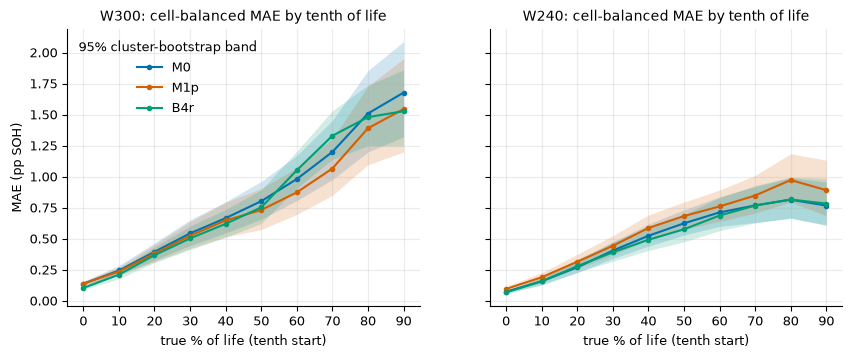

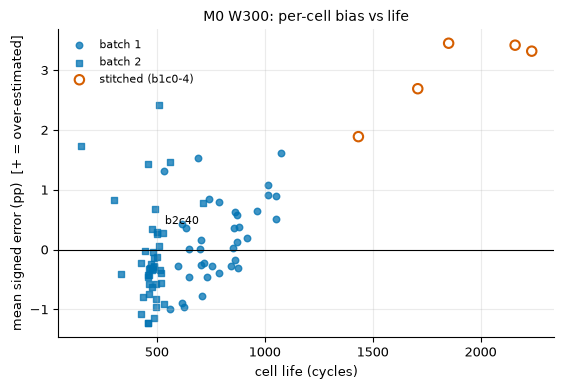

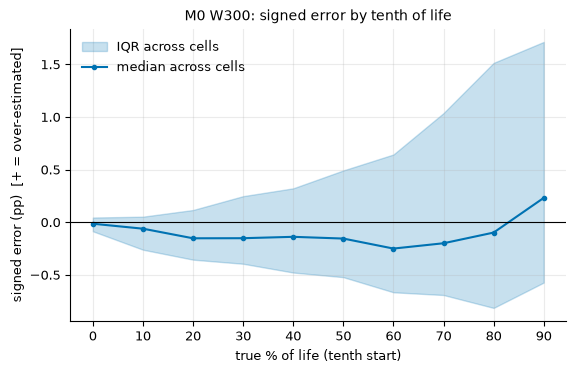

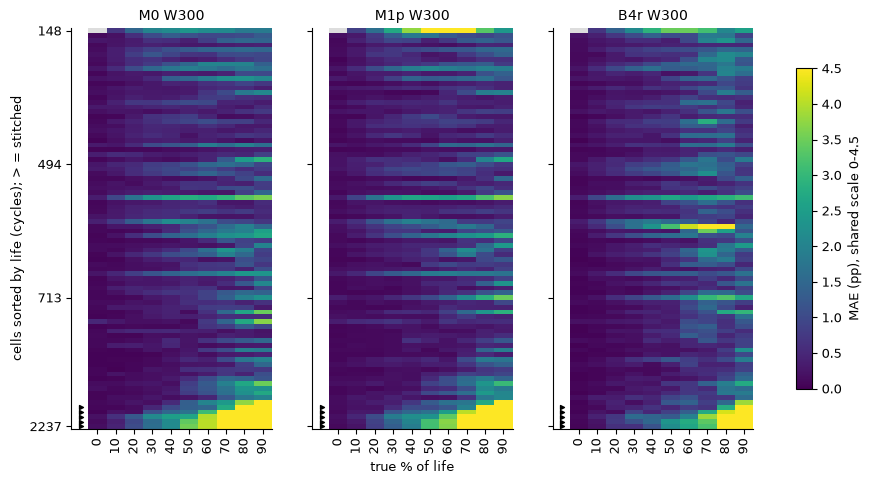

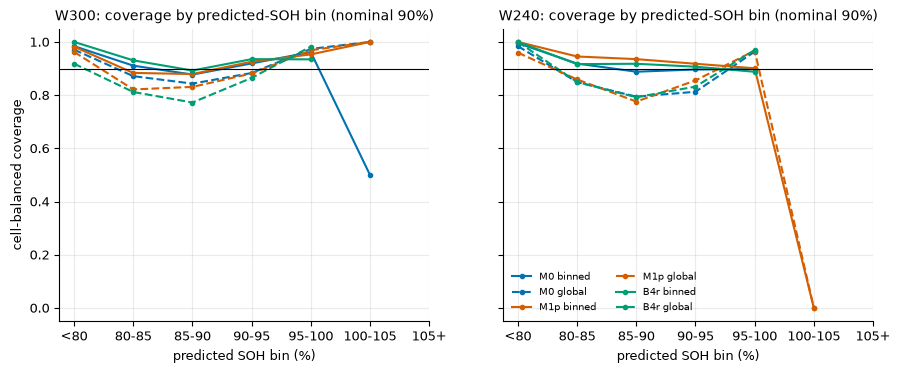

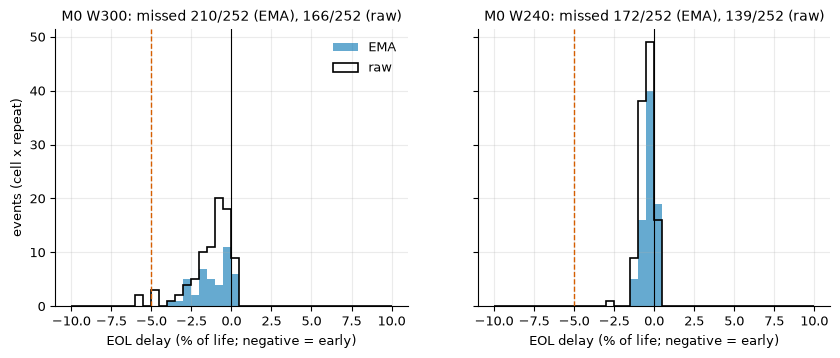

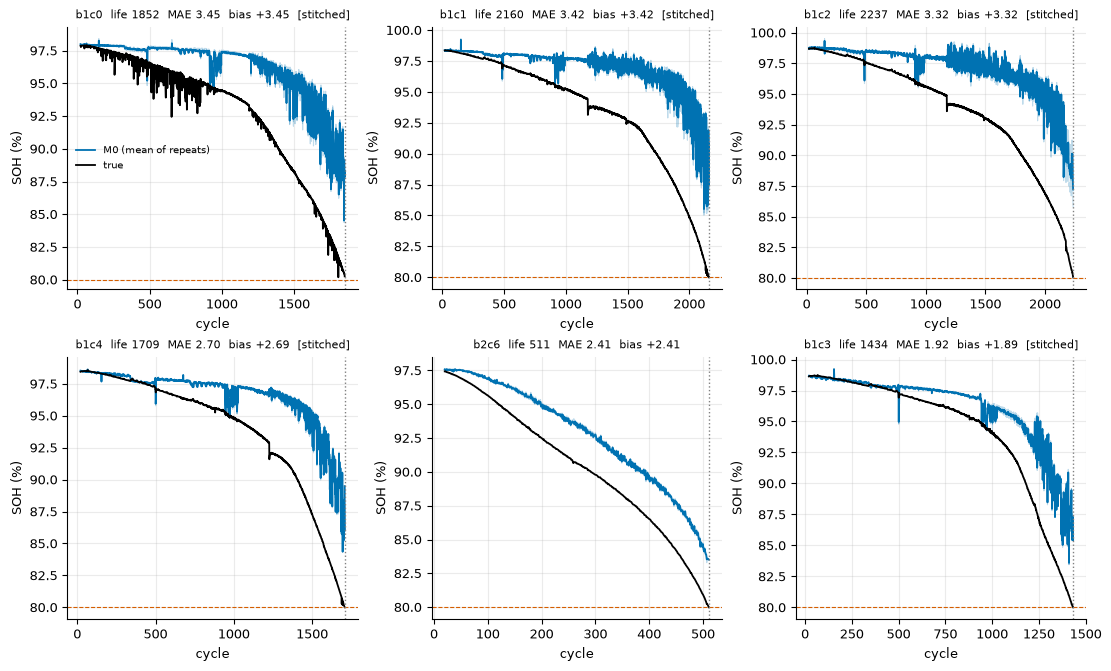

[PASS] figure written: fig_a_mae_by_tenth.png  |  101 KB
[PASS] figure written: fig_b_bias_vs_life_M0_W300.png  |  45 KB
[PASS] figure written: fig_c_signed_error_by_tenth_M0_W300.png  |  48 KB
[PASS] figure written: fig_d_heatmaps_W300.png  |  63 KB
[PASS] figure written: fig_e_coverage_by_pred_soh_bin.png  |  99 KB
[PASS] figure written: fig_f_eol_delay_hist_M0.png  |  45 KB
[PASS] figure written: fig_g_worst_cell_trajectories_M0_W300.png  |  236 KB


In [10]:
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.titlesize": 10, "figure.dpi": 100})
COL = {"M0": "#0072B2", "M1p": "#D55E00", "B4r": "#009E73", "B3r": "#CC79A7"}
XT = [t.split("-")[0] for t in TENTH_LAB]

# (a) MAE vs tenth of life with bootstrap bands
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, w in zip(axs, ["W300", "W240"]):
    for m in ["M0", "M1p", "B4r"]:
        t = stage_df[(stage_df.window == w) & (stage_df.model == m) & (stage_df.stage == "tenth_of_life")]
        ax.plot(range(10), t.macro_mae, color=COL[m], marker="o", ms=3, label=m)
        ax.fill_between(range(10), t.ci95_lo, t.ci95_hi, color=COL[m], alpha=0.18, lw=0)
    ax.set_xticks(range(10)); ax.set_xticklabels(XT); ax.set_xlabel("true % of life (tenth start)"); ax.set_title(f"{w}: cell-balanced MAE by tenth of life")
axs[0].set_ylabel("MAE (pp SOH)"); axs[0].legend(frameon=False, title="95% cluster-bootstrap band")
save_fig(fig, "fig_a_mae_by_tenth.png")

# (b) per-cell bias vs life, M0 W300
cm = CM[("W300", "M0")]
fig, ax = plt.subplots(figsize=(6.4, 4))
for b, mk in [(1, "o"), (2, "s")]:
    k = (BATCH == b) & ~IS_ST
    ax.scatter(LIFE[k], cm["bias"][k], marker=mk, s=22, color=COL["M0"], alpha=0.75, label=f"batch {b}")
ax.scatter(LIFE[IS_ST], cm["bias"][IS_ST], marker="o", s=46, facecolor="none", edgecolor="#D55E00", lw=1.5, label="stitched (b1c0-4)")
d = int(np.where(IS_DEF)[0][0]); ax.annotate(DEFECTIVE, (LIFE[d], cm["bias"][d]), xytext=(6, 6), textcoords="offset points", fontsize=8)
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("cell life (cycles)"); ax.set_ylabel("mean signed error (pp)  [+ = over-estimated]"); ax.set_title("M0 W300: per-cell bias vs life")
ax.legend(frameon=False, fontsize=8)
save_fig(fig, "fig_b_bias_vs_life_M0_W300.png")

# (c) signed error vs true tenth, median and IQR across cells
Ms = STAGE[("W300", "M0", "tenth_of_life")]["Msg"]
q25, q50, q75 = np.nanpercentile(Ms, [25, 50, 75], axis=0)
fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.fill_between(range(10), q25, q75, color=COL["M0"], alpha=0.22, label="IQR across cells")
ax.plot(range(10), q50, color=COL["M0"], marker="o", ms=3, label="median across cells")
ax.axhline(0, color="k", lw=0.8); ax.set_xticks(range(10)); ax.set_xticklabels(XT)
ax.set_xlabel("true % of life (tenth start)"); ax.set_ylabel("signed error (pp)  [+ = over-estimated]"); ax.set_title("M0 W300: signed error by tenth of life")
ax.legend(frameon=False)
save_fig(fig, "fig_c_signed_error_by_tenth_M0_W300.png")

# (d) heat maps of per-cell MAE by tenth, sorted by life, shared colour scale (M0 shown as the reference panel)
order = np.argsort(LIFE, kind="stable")
mats = {m: STAGE[("W300", m, "tenth_of_life")]["Mabs"][order] for m in ["M0", "M1p", "B4r"]}
vmax = HEATMAP_VMAX if HEATMAP_VMAX else float(np.ceil(np.nanpercentile(mats["M0"], 98) * 2) / 2)
cmap = plt.get_cmap("viridis").copy(); cmap.set_bad("#dddddd")
fig, axs = plt.subplots(1, 3, figsize=(11, 5.2), sharey=True)
st_rows = np.where(IS_ST[order])[0]
for ax, (m, M) in zip(axs, mats.items()):
    im = ax.imshow(np.ma.masked_invalid(M), aspect="auto", cmap=cmap, vmin=0, vmax=vmax, interpolation="nearest")
    ax.set_xticks(range(10)); ax.set_xticklabels(XT, rotation=90); ax.set_title(f"{m} W300"); ax.grid(False)
    ax.scatter(np.full(len(st_rows), -0.9), st_rows, marker=">", s=8, c="k", clip_on=False)
cuts = [int((TERT[order] == t).sum()) for t in range(3)]
axs[0].set_yticks([0, cuts[0], cuts[0] + cuts[1], NC - 1]); axs[0].set_yticklabels([f"{LIFE[order][i]:.0f}" for i in [0, cuts[0], cuts[0] + cuts[1], NC - 1]])
axs[0].set_ylabel("cells sorted by life (cycles); > = stitched"); axs[1].set_xlabel("true % of life")
fig.colorbar(im, ax=axs, shrink=0.8, label=f"MAE (pp), shared scale 0-{vmax:g}")
save_fig(fig, "fig_d_heatmaps_W300.png")

# (e) coverage by predicted-SOH bin
fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.8), sharey=True)
for ax, w in zip(axs, ["W300", "W240"]):
    for m in ["M0", "M1p", "B4r"]:
        for method, ls in [("binned", "-"), ("global", "--")]:
            t = confg_df[(confg_df.window == w) & (confg_df.model == m) & (confg_df.method == method) & (confg_df.group_type == "pred_soh_bin")]
            if len(t):
                ax.plot(range(len(PRED_LAB)), t.macro_coverage, ls=ls, color=COL[m], marker="o", ms=3, label=f"{m} {method}")
    ax.axhline(LEVEL, color="k", lw=0.8); ax.set_xticks(range(len(PRED_LAB))); ax.set_xticklabels(PRED_LAB)
    ax.set_xlabel("predicted SOH bin (%)"); ax.set_title(f"{w}: coverage by predicted-SOH bin (nominal {LEVEL:.0%})")
axs[0].set_ylabel("cell-balanced coverage"); axs[1].legend(frameon=False, fontsize=7, ncol=2)
save_fig(fig, "fig_e_coverage_by_pred_soh_bin.png")

# (f) EOL delay histograms, M0
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
allv = np.concatenate([EVENTS[(w, "M0", v, "eol80")].pct.dropna().values for w in ["W300", "W240"] for v in ["raw", "ema"]])
lo_, hi_ = np.nanpercentile(allv, [1, 99]) if allv.size else (-50, 50); bins = np.linspace(min(lo_, -10), max(hi_, 10), 41)
for ax, w in zip(axs, ["W300", "W240"]):
    ema, raw = EVENTS[(w, "M0", "ema", "eol80")], EVENTS[(w, "M0", "raw", "eol80")]
    ax.hist(ema.pct.dropna(), bins=bins, color=COL["M0"], alpha=0.6, label="EMA")
    ax.hist(raw.pct.dropna(), bins=bins, histtype="step", color="k", lw=1.2, label="raw")
    ax.axvline(0, color="k", lw=0.8); ax.axvline(EARLY_PCT, color="#D55E00", ls="--", lw=1)
    ax.set_xlabel("EOL delay (% of life; negative = early)"); ax.set_title(f"M0 {w}: missed {int(ema.missed.sum())}/{len(ema)} (EMA), {int(raw.missed.sum())}/{len(raw)} (raw)")
axs[0].set_ylabel("events (cell x repeat)"); axs[0].legend(frameon=False)
save_fig(fig, "fig_f_eol_delay_hist_M0.png")

# (g) true vs predicted SOH for the 6 worst M0 W300 cells
fig, axs = plt.subplots(2, 3, figsize=(11, 6.6), sharey=False, constrained_layout=True)
six = list(np.argsort(-CM[("W300", "M0")]["mae"], kind="stable")[:6])
for ax, c in zip(axs.ravel(), six):
    s, n = STARTS[c], COUNTS[c]
    for ri in range(R):
        ax.plot(CYC[s:s + n], PRED[("W300", "M0")][ri, s:s + n], color=COL["M0"], alpha=0.25, lw=0.8)
    ax.plot(CYC[s:s + n], PRED[("W300", "M0")][:, s:s + n].mean(0), color=COL["M0"], lw=1.3, label="M0 (mean of repeats)")
    ax.plot(CYC[s:s + n], Y[s:s + n], color="k", lw=1.3, label="true")
    ax.axhline(80, color="#D55E00", ls="--", lw=0.8); ax.axvline(LIFE[c], color="grey", ls=":", lw=1)
    tags = ["stitched"] * bool(IS_ST[c]) + [DEFECTIVE] * bool(IS_DEF[c])
    ax.set_title(f"{cells[c]}  life {LIFE[c]:.0f}  MAE {CM[('W300', 'M0')]['mae'][c]:.2f}  bias {CM[('W300', 'M0')]['bias'][c]:+.2f}" + (f"  [{', '.join(tags)}]" if tags else ""), fontsize=8)
    ax.set_xlabel("cycle"); ax.set_ylabel("SOH (%)")
axs[0, 0].legend(frameon=False, fontsize=7)
save_fig(fig, "fig_g_worst_cell_trajectories_M0_W300.png")
for p in sorted(FIG.glob("*.png")):
    check(f"figure written: {p.name}", p.stat().st_size > 0, f"{p.stat().st_size / 1024:.0f} KB")

## 9. Report, final checks and artifacts

In [11]:
# ------------------------------------------------------------------ table checks on the saved CSVs
def _no_nan(df, cols, label):
    bad = int(df[cols].isna().sum().sum())
    check(f"no NaN in headline table: {label}", bad == 0, f"{bad} NaN cells")


_ov = bias_df[bias_df.section == "overall"]
_no_nan(_ov, ["macro_mae", "macro_abs_bias", "macro_resid_sd", "share_sq_err_bias_macro", "oracle_mae_bias_removed", "mean_signed_err_macro", "share_cells_bias_pos"], "bias_decomposition (overall)")
_no_nan(stage_df[stage_df.n_cells > 0], ["macro_mae", "ci95_lo", "ci95_hi"], "stage_errors (populated groups)")
_no_nan(worst_df, ["cell_id", "life", "cell_mae", "bias"], "worst_cells")
_no_nan(sens_df, ["macro_mae", "ci95_lo", "ci95_hi"], "sensitivity_subsets")
_no_nan(pair_df, ["diff_macro_mae", "ci95_lo", "ci95_hi"], "sensitivity_paired")
_no_nan(sm_df, ["mae_raw", "mae_ema", "bias_raw", "bias_ema"], "event_metrics (smoothing)")
_no_nan(conf_df, ["macro_coverage", "cov_ci95_lo", "cov_ci95_hi", "macro_width", "pooled_coverage"], "conformal_coverage")
_covcols = ["macro_coverage", "cov_ci95_lo", "cov_ci95_hi", "pooled_coverage"]
check("coverage numbers in [0,1]",
      bool(((conf_df[_covcols] >= 0) & (conf_df[_covcols] <= 1)).all().all()) and
      bool(((confg_df[_covcols].dropna(how="all").fillna(0.5) >= 0) & (confg_df[_covcols].dropna(how="all").fillna(0.5) <= 1)).all().all()))
check("84 cells in overall tables", set(_ov.n_cells) == {NC} and set(conf_df.n_cells) == {NC} and set(sens_df[sens_df.subset == "all84"].n_cells) == {NC}
      and set(sens_df[sens_df.subset == "excl_stitched"].n_cells) == {79} and set(sens_df[sens_df.subset == "excl_both"].n_cells) == {78}
      and len(cells) == 84 and all(arr.shape[1] == N for arr in PRED.values()))
check("no batch-3 / sensitivity cells anywhere", not (set(worst_df.cell_id) | set(knee_df.cell_id) | set(cells)) & set(SENS_CELLS)
      and not any(str(c).startswith("b3") for c in set(worst_df.cell_id) | set(cells)))
check("all outputs written under outputs/phase6a only", all(OUT.resolve() in Path(p).resolve().parents for p in WRITTEN), f"{len(WRITTEN)} files")

# ------------------------------------------------------------------ fixed-width report
def tbl(df, cols, fm=None, hdr=None):
    fm = fm or {}; hdr = hdr or {}
    cell = lambda c, v: (fm[c](v) if c in fm else (f"{v:.3f}" if isinstance(v, (float, np.floating)) else str(v))) if not (isinstance(v, float) and np.isnan(v)) else "-"
    rows = [[cell(c, v) for c, v in zip(cols, r)] for r in df[cols].itertuples(index=False, name=None)]
    heads = [hdr.get(c, c) for c in cols]
    wd = [max(len(h), *(len(r[i]) for r in rows)) if rows else len(h) for i, h in enumerate(heads)]
    num = [pd.api.types.is_numeric_dtype(df[c]) and df[c].dtype != bool for c in cols]
    fmt_row = lambda r: "  ".join(x.rjust(wd[i]) if num[i] else x.ljust(wd[i]) for i, x in enumerate(r))
    return "\n".join([fmt_row(heads), "  ".join("-" * x for x in wd)] + [fmt_row(r) for r in rows])


pct = lambda v: f"{100 * v:.1f}%"
L = []
bar = "=" * 100
sec = lambda t: L.extend(["", bar, t, bar])
L += [bar, "PHASE 6a  FAILURE ANALYSIS, ERROR DECOMPOSITION, EOL EVENTS, CONFORMAL INTERVALS", bar,
      f"generated {datetime.datetime.now():%Y-%m-%d %H:%M}   root {ROOT}",
      "source: saved Phase 5b Protocol D out-of-fold predictions (seed-ensemble per row); nothing trained",
      "frozen verdict (not recomputed): headline W300 FAIL (M0 0.836 vs target 0.760); companion W240 PASS (M0 0.530 vs 0.557)",
      f"development rows {N:,} | cells {NC} (batch1 {int((BATCH == 1).sum())}, batch2 {int((BATCH == 2).sum())}) | repeats {R} | err = pred - y (+ = over-estimated)",
      f"life tertile cuts {LIFE_CUTS[0]:.0f} / {LIFE_CUTS[1]:.0f} cycles | bootstrap: cells resampled, {B_BOOT} draws, seed {SEED_BOOT}"]
sec("1. REPRODUCTION OF PHASE 5b (cell-macro MAE vs deep_results.csv macro_mean)")
L.append(tbl(REPRO, ["window", "model", "recomputed_macro_mae", "deep_results_macro_mean", "abs_diff"],
             {"recomputed_macro_mae": lambda v: f"{v:.6f}", "deep_results_macro_mean": lambda v: f"{v:.6f}", "abs_diff": lambda v: f"{v:.1e}"}))
sec("2. BIAS VS NOISE  (oracle_mae = each cell's own mean error subtracted: ORACLE DIAGNOSTIC, uses test labels)")
L.append(tbl(_ov, ["window", "model", "macro_mae", "macro_abs_bias", "macro_resid_sd", "share_sq_err_bias_macro", "oracle_mae_bias_removed", "pooled_signed_err", "share_cells_bias_pos"],
             {"share_sq_err_bias_macro": pct, "share_cells_bias_pos": pct, "pooled_signed_err": lambda v: f"{v:+.3f}"},
             {"share_sq_err_bias_macro": "bias_share_sq", "oracle_mae_bias_removed": "oracle_mae", "pooled_signed_err": "pooled_bias", "share_cells_bias_pos": "cells_bias>0"}))
L.append("positive pooled bias = optimistic over-estimation: " + "; ".join(f"{r.window} {r.model} {'yes' if r.pooled_signed_err > 0 else 'NO'}" for r in _ov.itertuples()))
sec("3. STAGE ANALYSIS  (cell-balanced MAE, 95% cluster-bootstrap CI)")
for w in ["W300", "W240"]:
    for m in ["M0", "B4r"]:
        t = stage_df[(stage_df.window == w) & (stage_df.model == m)].copy()
        t["ci95"] = [f"[{a:.3f}, {b:.3f}]" for a, b in zip(t.ci95_lo, t.ci95_hi)]
        L += ["", f"{w} {m}", tbl(t, ["stage", "group", "n_cells", "macro_mae", "ci95", "macro_signed_err"], {"macro_signed_err": lambda v: f"{v:+.3f}"})]
L += ["", f"knee onset (oracle diagnostic): median {knee_df.knee_pct_of_life.median():.0f}% of life, IQR {knee_df.knee_pct_of_life.quantile(.25):.0f}-{knee_df.knee_pct_of_life.quantile(.75):.0f}%"]
sec("4. WORST CELLS  (5 per model; constant-offset |bias|>70% of MAE; late-growth last-tenth MAE >3x first-tenth)")
L.append(tbl(worst_df, ["window", "model", "rank", "cell_id", "batch", "life", "cell_mae", "bias", "repeats_above_train_range", "repeats_below_train_range",
                        "tag_stitched", "tag_b2c40", "rows_dropped_by_masks", "flag_cycles_cycles_table", "flag_rows_labels", "tag_dirty", "error_type"],
             {"life": lambda v: f"{v:.0f}", "bias": lambda v: f"{v:+.3f}", "flag_cycles_cycles_table": lambda v: f"{v:.0f}"},
             {"repeats_above_train_range": "above_tr", "repeats_below_train_range": "below_tr", "rows_dropped_by_masks": "rows_masked", "flag_cycles_cycles_table": "flag_cyc", "flag_rows_labels": "flag_rows"}))
sec(f"5. SENSITIVITY SUBSETS (macro MAE; DESCRIPTIVE; {N_INTERVALS} intervals in total, a few will exclude zero by chance)")
L.append(pv.reset_index().pipe(lambda d: tbl(d, list(d.columns))))
L += ["", "paired cluster-bootstrap contrasts (negative = first model better)",
      tbl(pair_df.assign(ci95=[f"[{a:+.3f}, {b:+.3f}]" for a, b in zip(pair_df.ci95_lo, pair_df.ci95_hi)]),
          ["window", "subset", "contrast", "n_cells", "diff_macro_mae", "ci95", "ci_excludes_zero"], {"diff_macro_mae": lambda v: f"{v:+.3f}"})]
sec("6. EVENT METRICS  (causal EMA, alpha chosen on other folds; delay = est - true, negative = early; early > 5% of life)")
L.append(tbl(sm_df, ["window", "model", "mae_raw", "mae_ema", "bias_raw", "bias_ema", "alpha_counts"], {"bias_raw": lambda v: f"{v:+.3f}", "bias_ema": lambda v: f"{v:+.3f}"}))
L.append("EMA lag on a falling curve over-estimates SOH (positive shift in signed error): " +
         "; ".join(f"{r.window} {r.model} {r.bias_change:+.3f} pp" for r in sm_df.itertuples()))
L += ["", tbl(evt_df, ["window", "model", "variant", "alert", "subset", "n_events", "missed_rate", "early_alarm_rate", "median_delay_cycles", "median_delay_pct_life", "mae_delay_pct_life"],
              {"missed_rate": pct, "early_alarm_rate": pct, "median_delay_cycles": lambda v: f"{v:+.0f}", "median_delay_pct_life": lambda v: f"{v:+.1f}", "mae_delay_pct_life": lambda v: f"{v:.1f}"},
              {"median_delay_pct_life": "med_delay_%life", "mae_delay_pct_life": "mae_delay_%life"})]
sec("7. CONFORMAL INTERVALS  (split-conformal, nominal 90%; APPROXIMATE: calibration folds' models saw the test fold's cells)")
L.append(tbl(conf_df.assign(cov_ci95=[f"[{a:.3f}, {b:.3f}]" for a, b in zip(conf_df.cov_ci95_lo, conf_df.cov_ci95_hi)]),
             ["window", "model", "method", "macro_coverage", "cov_ci95", "macro_width", "min_cell_coverage", "share_cells_cov_below_0p80", "share_misses_over_estimate"],
             {"share_cells_cov_below_0p80": pct, "share_misses_over_estimate": pct}, {"share_cells_cov_below_0p80": "cells<0.80", "share_misses_over_estimate": "miss_over%"}))
for gt in ["life_tertile", "stitched", "batch", "pred_soh_bin", "true_tenth"]:
    t = confg_df[(confg_df.group_type == gt) & (confg_df.method == "binned") & (confg_df.window == "W300") & (confg_df.model.isin(["M0", "B4r"]))]
    L += ["", f"coverage / width by {gt} (binned method, W300)",
          tbl(t, ["model", "group", "n_cells", "macro_coverage", "macro_width", "share_misses_over_estimate"], {"share_misses_over_estimate": pct}, {"share_misses_over_estimate": "miss_over%"})]
sec("8. CHECKS")
_chk_pre = {lv: sum(c["level"] == lv for c in CHECKS) for lv in ["PASS", "WARN", "FAIL", "INFO"]}
L.append(f"so far: {_chk_pre}")
for c in CHECKS:
    if c["level"] in ("WARN", "FAIL"):
        L.append(f"  [{c['level']}] {c['name']} | {c['detail']}")

# ------------------------------------------------------------------ artifacts, final hash checks, verification report
_report_path = save_text("\n".join(L) + "\n", "phase6a_report.txt")
HASH1 = hash_state()
for _k, _lab in [("gate", "week2_gate.json"), ("module", "soh_deep_v2.py"), ("verdict", "gate_verdict.json")]:
    check(f"sha256 unchanged at end: {_lab}", HASH1[_k]["ok"] and HASH1[_k]["raw"] == HASH0[_k]["raw"], HASH1[_k]["lf" if _k == "module" else "raw"][:16] + "...")
check("verdict file not touched (mtime unchanged)", HASH1["verdict"]["mtime_ns"] == HASH0["verdict"]["mtime_ns"])
check("frozen gate and module not touched (mtime unchanged)", HASH1["gate"]["mtime_ns"] == HASH0["gate"]["mtime_ns"] and HASH1["module"]["mtime_ns"] == HASH0["module"]["mtime_ns"])


def artifact_list():
    return [{"file": str(p.relative_to(OUT)).replace("\\", "/"), "bytes": p.stat().st_size} for p in sorted(OUT.rglob("*")) if p.is_file()]


art = artifact_list()
dump_checks(partial=False, extra={"artifacts": art, "elapsed_seconds": round(time.time() - T0, 1),
                                  "hashes": {"start": HASH0, "end": HASH1}, "verdict_frozen": "W300 FAIL (M0 0.836 vs 0.760); W240 PASS (M0 0.530 vs 0.557)"})
art = artifact_list()
_n = lambda s: sum(c["level"] == s for c in CHECKS)
print(_report_path.read_text(encoding="utf-8"))
print(f"\nFINAL CHECKS: PASS {_n('PASS')} | WARN {_n('WARN')} | FAIL {_n('FAIL')} | INFO {_n('INFO')}   (elapsed {time.time() - T0:.0f}s)")
print("\nARTIFACTS (outputs/phase6a)")
print(pd.DataFrame(art).assign(KB=lambda d: (d.bytes / 1024).round(1)).drop(columns="bytes").to_string(index=False))

[PASS] no NaN in headline table: bias_decomposition (overall)  |  0 NaN cells
[PASS] no NaN in headline table: stage_errors (populated groups)  |  0 NaN cells
[PASS] no NaN in headline table: worst_cells  |  0 NaN cells
[PASS] no NaN in headline table: sensitivity_subsets  |  0 NaN cells
[PASS] no NaN in headline table: sensitivity_paired  |  0 NaN cells
[PASS] no NaN in headline table: event_metrics (smoothing)  |  0 NaN cells
[PASS] no NaN in headline table: conformal_coverage  |  0 NaN cells
[PASS] coverage numbers in [0,1]
[PASS] 84 cells in overall tables
[PASS] no batch-3 / sensitivity cells anywhere
[PASS] all outputs written under outputs/phase6a only  |  17 files
[PASS] sha256 unchanged at end: week2_gate.json  |  40df2fb82096e994...
[PASS] sha256 unchanged at end: soh_deep_v2.py  |  fc53e37d506ebe51...
[PASS] sha256 unchanged at end: gate_verdict.json  |  2f59f82a7c7d8940...
[PASS] verdict file not touched (mtime unchanged)
[PASS] frozen gate and module not touched (mtime unc